In [1]:
#IMPORTS
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import PowerTransformer
from kmodes.kprototypes import KPrototypes
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import itertools
from tqdm.auto import tqdm
import seaborn as sns
import pandas as pd
import numpy as np
import gower

c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#CONFIGURACOES
# ---- nao truncar impressao do pandas ---- #
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)
# ----------------------------------------- #

# Tarefa A - Modelo

# Preparando para treinar o modelo

In [16]:
#CONFIGURACOES DO MODELO (DEFININDO OS VALORES + GRID)
DATA_PATH = "dados/Dados_REG_limpo_kprototype.csv"

NUM_COLS = [                # col. numericas
    "Atividade 02",
    "Atividade 05",
    "Atividade 06",
    "Atividade 07",
    "Atividade 08",
    "Atividade 09",
    "Atividade 10",
    "Atividade 11",
    "Atividade 12",
    "Atividade 14",
    "Atividade 15",
    "Atividade 13",###""
    "Atividade 01",
    "Atividade 17",
    "Atividade 18",
    "Atividade 19",
    "Atividade 20",
    "Atividade 21",
    "Atividade 22",####""
    "Atividade 23"
]
CAT_COLS = [                # col. categoricas
    "GRAM",
    "Cores",
    "Borda", 
    "Textura",
    "Forma",
    "Brilho",
    "Muco", 
    "Relevo",
    "Atividade 03",
    "Atividade 04",
    "Atividade 16"
]    
MORFOLOGIA = [                # col. categoricas
    "GRAM",
    "Cores",
    "Borda", 
    "Textura",
    "Forma",
    "Brilho",
    "Muco", 
    "Relevo",
]

#Definindo hiperparametros para serem usados na grid
PARAM_GRID = { # mapa dos hiperparametros
    "n_clusters": [2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
    "gamma": [0.125, 0.25, 0.5, 1.0, 2.0],  #gamma alto -> cat vale mais na dist | gamma baixo -> num vale mais na dist
    "init": ["Cao"]
}
N_INIT_HUANG = 5
MAX_ITER = 100              # max. iteracoes
N_JOBS = -1                 # -1 p/ usar tds nucleos do PC
RND_STATE = 42              # val. aleatorio pre-definido p/ ter consistencia nos resultados

#Config. sobre o calculo de estabilidade do modelo
COMPUTE_STABILITY = True    # define se vai ser calc. estabilidade
STABILITY_FRAC = 0.7        # fraciona quantas amostras sao usadas do conj. original 

MIN_CLUSTER_FRAC = 0.05     # menor cluster >= 5% dos dados
MIN_STABILITY = 0.70        # ARI min

In [4]:
#PREPARANDO OS VALORES PARA TREINAMENTO
df = pd.read_csv(DATA_PATH, sep="\t").dropna(subset=NUM_COLS + CAT_COLS).reset_index(drop=True)
n = len(df)

# normalizando somente os valores numericos
X_num_scaled = PowerTransformer(
    method='yeo-johnson',   # funciona com valores positivos e negativos
    standardize=True        # normaliza os dados depois
).fit_transform(df[NUM_COLS].astype(float))

# criando matriz do tipo "object" para manter tanto os valores cat. quanto num.
X = np.empty((n, len(NUM_COLS) + len(CAT_COLS)), dtype=object)
X[:, :len(NUM_COLS)] = X_num_scaled
X[:, len(NUM_COLS):] = df[CAT_COLS].astype(str).to_numpy()
CAT_IDX = list(range(len(NUM_COLS), len(NUM_COLS) + len(CAT_COLS)))

# calc o gamma base para depois multiplicar pelo hiperparametros 
# biblioteca base define este como o gamma base (se nao preencheu gamma nos hiperparam.)
base_gamma = 0.5 * X[:, :len(NUM_COLS)].std().mean()

# obs.: para evitar qualquer problema foi removido qualquer linha com valores nulos
print(f"{n} linhas | {len(NUM_COLS)} numéricas | {len(CAT_COLS)} categóricas")

503 linhas | 20 numéricas | 11 categóricas


In [5]:
#CALCULANDO DISTANCIA GOWER PARA COMPARAR COM RESULTADOS DEPOIS
# distancia de gower eh uma metrica de dissimilaridade que compara 
# 2 amostras (compara 1 para todas, em todas as amostras), fazendo
# uma media entre todas as distancias.

# neste caso, Gower esta sendo usado para comparar o quao similar
# sao 2 amostras de um mesmo cluster

# pega a qtd de linhas do df (define dimensoes da matriz)
eval_idx = np.arange(n)
X_eval = X

eval_df = df[NUM_COLS + CAT_COLS].copy()
eval_df[CAT_COLS] = eval_df[CAT_COLS].astype(str)
is_cat = [c in CAT_COLS for c in eval_df.columns]

D_eval = gower.gower_matrix(eval_df, cat_features=is_cat)

# gower calc. assim todas a similaridade entre todas as amostras
# do dataset
print("Matriz de Gower:", D_eval.shape)

Matriz de Gower: (503, 503)


# Treinando o modelo

In [6]:
#Cria o modelo (usado p/ grid)
def build_model(params, seed=RND_STATE):
    gamma = base_gamma * params["gamma"]
    return KPrototypes(
        n_clusters=params["n_clusters"],
        gamma=gamma,
        init=params["init"],
        n_init=N_INIT_HUANG if params["init"] != "Cao" else 1,
        max_iter=MAX_ITER,
        n_jobs=N_JOBS,
        random_state=seed,
    )

#Avalia a qualidade do modelo, comparando com silhuette e gower
def evaluate(params):
    model = build_model(params)

    # labels -> apos treino o modelo da uma etiqueta de qual cluster a amostra 
    # pertence
    labels = model.fit_predict(X, categorical=CAT_IDX)

    # conta quantas amostras tem em cada cluster
    counts = np.bincount(labels, minlength=params["n_clusters"])

    # pega os rotulos das amostras usadas no calc. da matriz Gower e
    # calcula a silhueta
    # +-> Silhouette determina qualidade de agrupamento, medindo quao
    #     bem posicionado uma amostra eh dentro de seu cluster
    #     - Proximo de 1 = amostras bem agrupadas e afastadas de outros clusters
    #     - Proximo de 0 = amostras proximas da fronteira entre cluster (ou 
    #       clusters pouco separados)
    #     - Negativo = amostras mais proximas de outro cluster do que do proprio
    sil = (silhouette_score(D_eval, labels, metric="precomputed")
           if len(np.unique(labels)) > 1 else np.nan)
    # obs.: "precomputed" diz que a entrada eh uma matriz de distancias ja calculada 
    # (neste caso, Matriz Gower (ou D_eval))
    
    # estabilidade determina se o modelo produz agrupamentos parecidos se for treinado
    # com diferentes subconj. dos dados
    stab = np.nan
    if COMPUTE_STABILITY:
        # guarda os agrup. de todas as exec. do teste de estabilidade
        preds = []

        # exec. o for 2 vezes com seeds diferentes
        for seed in (1, 2):
            r = np.random.default_rng(RND_STATE + seed)

            # escolhendo quais sao as sub-amostras a serem escolhidas
            sub = r.choice(n, size=int(n * STABILITY_FRAC), replace=False)

            # cria modelo com as sub-amostras
            m = build_model(params, seed=RND_STATE + seed)

            # treina com o subconj. e salva a predicao em "preds"
            m.fit(X[sub], categorical=CAT_IDX)
            preds.append(m.predict(X_eval, categorical=CAT_IDX))

        # usa ARI p/ definir a estabilidade
        stab = adjusted_rand_score(preds[0], preds[1])
        # ARI (Adjusted Rand Index) mede o grau de concordancia entre
        # dois agrup. (compara se os pares de amostras foram agrupados
        # juntos ou separados em cada exec., ajustando concordancia
        # esperada pelo acaso)
        # +-> ARI = 1 -> agrup. identicos
        # +-> ARI proximo de 0 -> concordancia proxima a esperada pelo acaso
        # +-> ARI < 0 -> concordancia inferior a esperada pelo acaso

    return {**params,
            "silhouette_gower": sil,
            "stability_ari": stab,
            "min_cluster_frac": counts.min() / n, # checa se teve algum cluster
                                                  # muito pequeno (PODE indicar
                                                  # que "k" eh muito grande) 
            "cost": model.cost_,
            "labels": model.labels_}

In [ ]:
keys = list(PARAM_GRID)

# "itertools.product" gera todas as combinacoes possiveis de hiperparam.
combos = [dict(zip(keys, v)) for v in itertools.product(*PARAM_GRID.values())]
print(f"{len(combos)} combinações")

results = []
for params in tqdm(combos):
    try:
        results.append(evaluate(params))
    except Exception as e:
        print("ERRO", params, e) 

res = pd.DataFrame(results)
res.to_csv("dados/resultados_grid.csv", index=False)
res.sort_values("silhouette_gower", ascending=False).head()

50 combinações


100%|██████████| 50/50 [00:30<00:00,  1.64it/s]


,n_clusters,gamma,init,silhouette_gower,stability_ari,min_cluster_frac,cost,labels
4,2,2.000,Cao,0.130224,0.883501,0.373757,10304.546355,"[1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, ...]"
0,2,0.125,Cao,0.129643,0.810396,0.357853,8781.393139,"[1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, ...]"
1,2,0.250,Cao,0.129643,0.861537,0.357853,8883.330639,"[1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, ...]"
2,2,0.500,Cao,0.129643,0.861523,0.357853,9087.205639,"[1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, ...]"
3,2,1.000,Cao,0.129492,0.944844,0.363817,9493.933585,"[1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, ...]"


In [8]:
#FILTRANDO APENAS OS MODELOS COM UM MINIMO DE ESTABILIDADE E CLUSTER MINIMO
ok = res[res["min_cluster_frac"] >= MIN_CLUSTER_FRAC]
if COMPUTE_STABILITY:
    ok = ok[ok["stability_ari"] >= MIN_STABILITY]
if ok.empty:
    print("Nenhum modelo passou nos filtros; mostrando todos.")
    ok = res

ranking = ok.sort_values("silhouette_gower", ascending=False).reset_index(drop=True)
display(ranking.head(10))

,n_clusters,gamma,init,silhouette_gower,stability_ari,min_cluster_frac,cost,labels
0,2,2.000,Cao,0.130224,0.883501,0.373757,10304.546355,"[1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, ...]"
1,2,0.125,Cao,0.129643,0.810396,0.357853,8781.393139,"[1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, ...]"
2,2,0.250,Cao,0.129643,0.861537,0.357853,8883.330639,"[1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, ...]"
3,2,0.500,Cao,0.129643,0.861523,0.357853,9087.205639,"[1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, ...]"
4,2,1.000,Cao,0.129492,0.944844,0.363817,9493.933585,"[1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, ...]"
5,3,2.000,Cao,0.097300,0.935218,0.324056,9364.548262,"[1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 2, 0, 2, 1, 2, 0, 1, 0, 2, 0, 0, 1, 0, 0, 1, 1, 2, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 2, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 2, 0, 1, 2, 1, 2, 2, 0, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, ...]"
6,3,1.000,Cao,0.096534,0.952625,0.326044,8571.547415,"[1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 2, 0, 2, 1, 2, 0, 1, 0, 2, 0, 0, 1, 0, 0, 1, 1, 2, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 2, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 2, 0, 1, 2, 1, 2, 2, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, ...]"
7,3,0.125,Cao,0.096449,0.935023,0.322068,7876.860667,"[1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 2, 0, 2, 1, 2, 0, 1, 0, 2, 0, 0, 1, 0, 0, 1, 1, 2, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 2, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 2, 0, 1, 2, 1, 2, 2, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, ...]"
8,3,0.250,Cao,0.096373,0.976313,0.322068,7976.052794,"[1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 2, 0, 2, 1, 2, 0, 1, 0, 2, 0, 0, 1, 0, 0, 1, 1, 2, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 2, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 2, 0, 1, 2, 1, 2, 2, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, ...]"
9,3,0.500,Cao,0.096293,0.976330,0.324056,8174.725634,"[1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 2, 0, 2, 1, 2, 0, 1, 0, 2, 0, 0, 1, 0, 0, 1, 1, 2, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 2, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 2, 0, 1, 2, 1, 2, 2, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, ...]"


# Visualizando resultados de treinamento

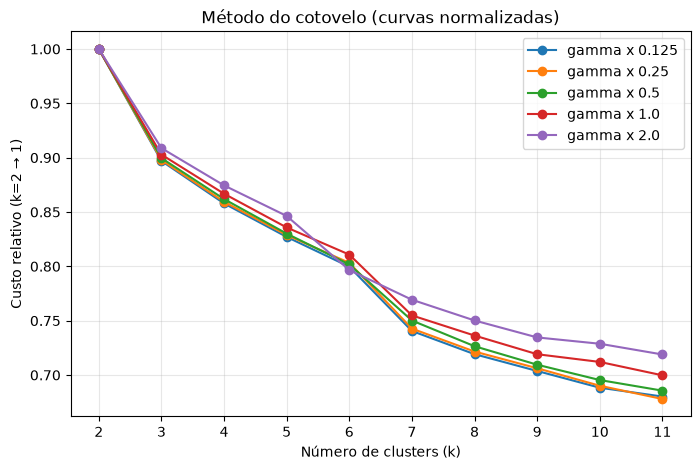

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))

for mult, g in res.groupby("gamma"):
    g = g.sort_values("n_clusters")
    ax.plot(g["n_clusters"], g["cost"] / g["cost"].iloc[0], marker="o", label=f"gamma x {mult}")

ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Custo relativo (k=2 → 1)")
ax.set_title("Método do cotovelo (curvas normalizadas)")
ax.set_xticks(sorted(res["n_clusters"].unique()))
ax.legend(); ax.grid(alpha=0.3)
plt.show()

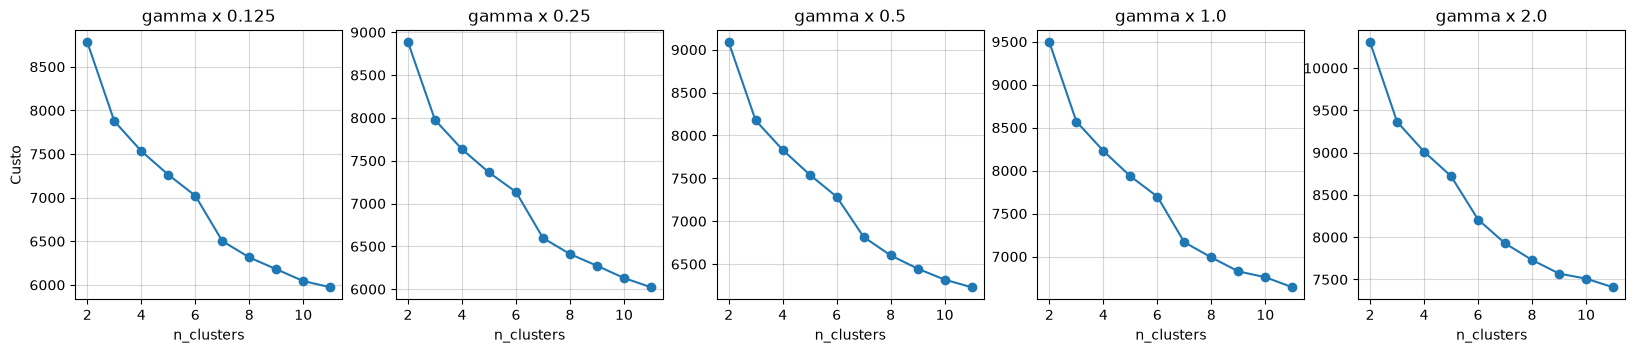

In [10]:
mults = sorted(res["gamma"].unique())
fig, axes = plt.subplots(1, len(mults), figsize=(4 * len(mults), 3.5))

for ax, mult in zip(axes, mults):
    g = res[res["gamma"] == mult].sort_values("n_clusters")
    ax.plot(g["n_clusters"], g["cost"], marker="o")
    ax.set_title(f"gamma x {mult}")
    ax.set_xlabel("n_clusters")
    ax.grid(alpha=0.5)

axes[0].set_ylabel("Custo")
plt.show()

O que se atentar no método do cotovelo:
- Procurar o ponto onde a curva deixa de despencar e passa a cair devagar
- Curva suave, sem joelho nenhum significa que os dados talvez não tenham uma estrutura de grupos clara
- Não compare a altura de cada linha (gamma modifica esse valor artificialmente)


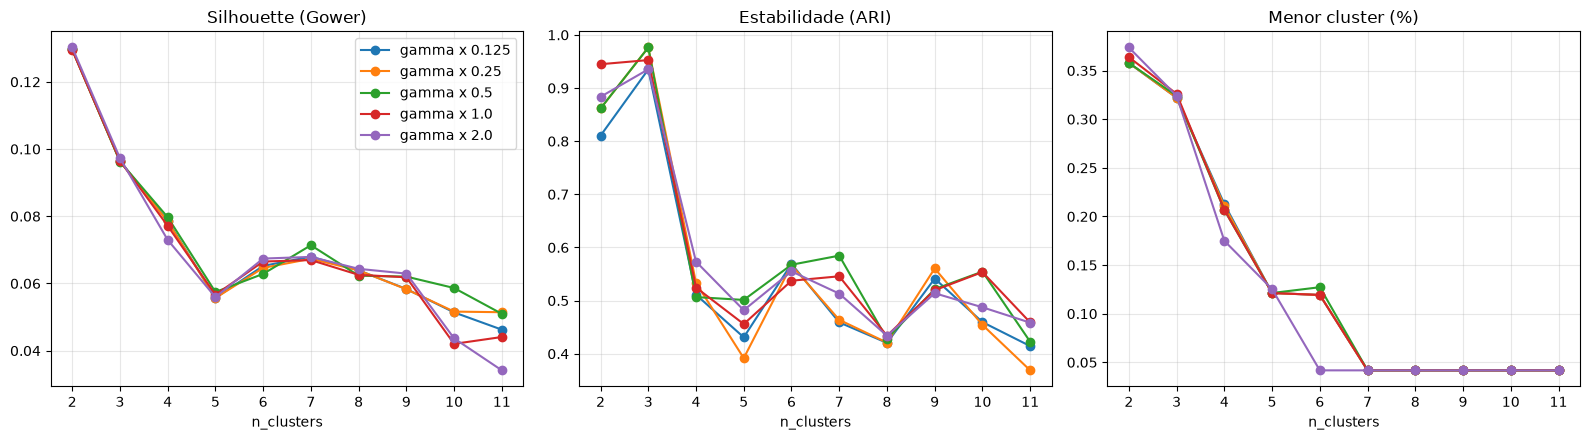

In [11]:
metricas = [
    ("silhouette_gower", "Silhouette (Gower)"),
    ("stability_ari", "Estabilidade (ARI)"),
    ("min_cluster_frac", "Menor cluster (%)"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (col, titulo) in zip(axes, metricas):
    for mult, g in res.groupby("gamma"):
        g = g.sort_values("n_clusters")
        ax.plot(g["n_clusters"], g[col], marker="o", label=f"gamma x {mult}")
    ax.set_title(titulo)
    ax.set_xlabel("n_clusters")
    ax.set_xticks(sorted(res["n_clusters"].unique()))
    ax.grid(alpha=0.3)

axes[0].legend()
plt.tight_layout()
plt.show()

Este conjunto de graficos busca definir o "k" em que gamma tem grupos bem separados, repetiveis e sem clusters residuais. Buscar pelo menos a combinação de 2 ou 3 valores de "k".
<br>
<br>

O que procurar no Shilhouette (Gower)
- Valores acima de ~0,5 é bom, 0,25 a 0,5 é fraco mas aceitavel
- Valores abaixo de ~0,25 indica estrutura fraca

O que procurar em Estabilidade (ARI)
- Valores acima de ~0,8 
- Queda brusca a partir de um certo "k" indica que dali em diante os clusters viram ruido
- Silhouette alto com ARI baixo = resultado é fragil

O que procurar em Menor Cluster (%)
- Valores acima de ~1-2%
- Cluster com menos de 1% indica provavel outlier, não segmento

Obs.: se todas as linhas se comportarem de forma parecida, o resultado é robusto à escolha de gamma.

# Modelo final

In [ ]:
k_final = 3
mult_final = 1
labels = KPrototypes(
    n_clusters=k_final, 
    init="Cao",
    gamma=base_gamma * mult_final, 
    random_state=RND_STATE, 
    n_jobs=-1
).fit_predict(X, categorical=CAT_IDX)

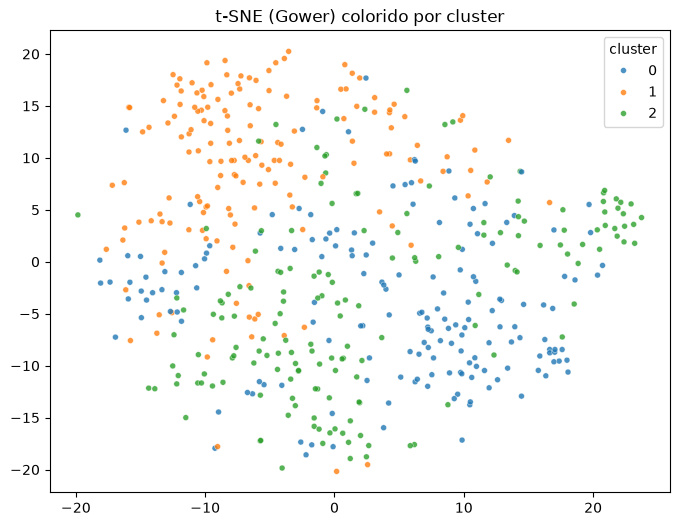

In [13]:
emb = TSNE(
    n_components=2, 
    metric="precomputed", 
    init="random",         
    perplexity=30, 
    random_state=RND_STATE
).fit_transform(D_eval.astype(float))

#labels = np.asarray(resF.loc[0, "labels"])


plt.figure(figsize=(8, 6))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=labels,
                palette="tab10", s=18, alpha=0.8)
plt.title("t-SNE (Gower) colorido por cluster")
plt.legend(title="cluster")
plt.show()

In [17]:
#CARACTERIZANDO OS CLUSTERS
df_analise = df.copy()
df_analise['Cluster'] = labels

#Tamanho de cada grupo
tamanho_grupos = df_analise['Cluster'].value_counts().sort_index()

percentual_grupos = (
    df_analise['Cluster'].value_counts(normalize=True).sort_index() * 100
)

tamanho = pd.DataFrame({
    'Quantidade': tamanho_grupos,
    'Percentual': percentual_grupos
})

#Perfil medio
perfil_atividades = df_analise.groupby('Cluster')[NUM_COLS].mean()

#Moda dos morfologicos
moda_morfologia = df_analise.groupby('Cluster')[MORFOLOGIA].agg(
    lambda x: x.mode().iloc[0] if not x.mode().empty else None
)

caracterizacao = pd.concat([
    tamanho,
    perfil_atividades,
    moda_morfologia
], axis=1)

print(caracterizacao)

         Quantidade  Percentual  Atividade 02  Atividade 05  Atividade 06  \
Cluster                                                                     
0               173   34.393638      1.881676      0.768613      0.007919   
1               164   32.604374      0.328049      0.739817      0.201220   
2               166   33.001988      0.595663      0.609880      0.062651   

         Atividade 07  Atividade 08  Atividade 09  Atividade 10  Atividade 11  \
Cluster                                                                         
0            0.134682      0.019480      0.496590      0.306069      0.184509   
1            0.140488      0.021829      0.778049      0.526890      0.288902   
2            0.093072      0.010422      0.914096      0.507711      0.348976   

         Atividade 12  Atividade 14  Atividade 15  Atividade 13  Atividade 01  \
Cluster                                                                         
0            0.137399      0.543584      0.549

In [ ]:
#SALVANDO OS LABELS EM CSV PARA USAR NA PARTE B

classe_kproto = pd.DataFrame(labels, columns=["Classe_K_PROTOTYPE"])
classe_kproto.to_csv('dados/Classe_K_PROTOTYPE.csv', index=False)
classe_kproto

,Classe_K_PROTOTYPE
0,1
1,0
2,0
3,1
4,0
5,1
6,0
7,1
8,1
9,0
